# Assignment 9 — Weather Reporting Agent Using a Free API

**Objective:** Create an agent that fetches and reports weather information using a free web API.

This agent takes a city name, finds its location using the Open-Meteo Geocoding API, fetches current weather data, and reports the result. It also displays the weather visually.

## How the agent works

The agent follows these steps:

1. Take a city name from the user.
2. Find the city's latitude and longitude.
3. Send those coordinates to the weather API.
4. Receive the current weather data.
5. Convert the weather code into a readable description.
6. Display the result and a simple visualization.

The notebook uses **Open-Meteo**, which provides weather and geocoding APIs without requiring an API key.

In [1]:
import requests
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

## Step 1 — Weather code descriptions

The API returns a numeric weather code. This function converts common WMO weather codes into readable descriptions.

In [2]:
def weather_description(code):
    descriptions = {
        0: "Clear sky",
        1: "Mainly clear",
        2: "Partly cloudy",
        3: "Overcast",
        45: "Fog",
        48: "Depositing rime fog",
        51: "Light drizzle",
        53: "Moderate drizzle",
        55: "Dense drizzle",
        61: "Slight rain",
        63: "Moderate rain",
        65: "Heavy rain",
        71: "Slight snow",
        73: "Moderate snow",
        75: "Heavy snow",
        80: "Slight rain showers",
        81: "Moderate rain showers",
        82: "Violent rain showers",
        95: "Thunderstorm",
        96: "Thunderstorm with slight hail",
        99: "Thunderstorm with heavy hail"
    }

    return descriptions.get(code, "Unknown weather condition")

## Step 2 — Find the city coordinates

Open-Meteo's geocoding service converts a city name into latitude and longitude.

In [3]:
def find_city(city):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": city,
        "count": 1,
        "language": "en",
        "format": "json"
    }

    response = requests.get(url, params=params, timeout=10)
    response.raise_for_status()
    data = response.json()

    if "results" not in data or not data["results"]:
        return None

    result = data["results"][0]

    return {
        "name": result.get("name", city),
        "country": result.get("country", "Unknown"),
        "latitude": result["latitude"],
        "longitude": result["longitude"]
    }

## Step 3 — Fetch current weather

The coordinates are passed to Open-Meteo's forecast service to get the current temperature, humidity, wind speed, and weather condition.

In [4]:
def get_weather(latitude, longitude):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "current": "temperature_2m,relative_humidity_2m,weather_code,wind_speed_10m",
        "timezone": "auto"
    }

    response = requests.get(url, params=params, timeout=10)
    response.raise_for_status()
    data = response.json()

    current = data["current"]

    return {
        "temperature": current["temperature_2m"],
        "humidity": current["relative_humidity_2m"],
        "weather_code": current["weather_code"],
        "wind_speed": current["wind_speed_10m"],
        "time": current["time"],
        "timezone": data.get("timezone", "Unknown")
    }

## Step 4 — Build the weather agent

This function combines the city search and weather API calls into one simple agent.

In [5]:
def weather_agent(city):
    try:
        location = find_city(city)

        if location is None:
            print("City not found. Please check the city name.")
            return None

        weather = get_weather(
            location["latitude"],
            location["longitude"]
        )

        return {
            "location": location,
            "weather": weather
        }

    except requests.exceptions.RequestException as error:
        print("Could not connect to the weather service.")
        print("Error:", error)
        return None

    except (KeyError, TypeError) as error:
        print("Unexpected data received from the API.")
        print("Error:", error)
        return None

## Step 5 — Test the agent

Change the city below if you want to test another location.

In [6]:
city = "Pune"

result = weather_agent(city)

if result:
    location = result["location"]
    weather = result["weather"]

    print("Weather Report")
    print("=" * 35)
    print("Location:", location["name"], ",", location["country"])
    print("Time:", weather["time"])
    print("Temperature:", weather["temperature"], "°C")
    print("Humidity:", weather["humidity"], "%")
    print("Wind speed:", weather["wind_speed"], "km/h")
    print("Condition:", weather_description(weather["weather_code"]))

Weather Report
Location: Pune , India
Time: 2026-09-15T14:45
Temperature: 28.9 °C
Humidity: 54 %
Wind speed: 14.0 km/h
Condition: Light drizzle


## Step 6 — Visualize the current weather

A small dashboard makes the API result easier to understand at a glance.

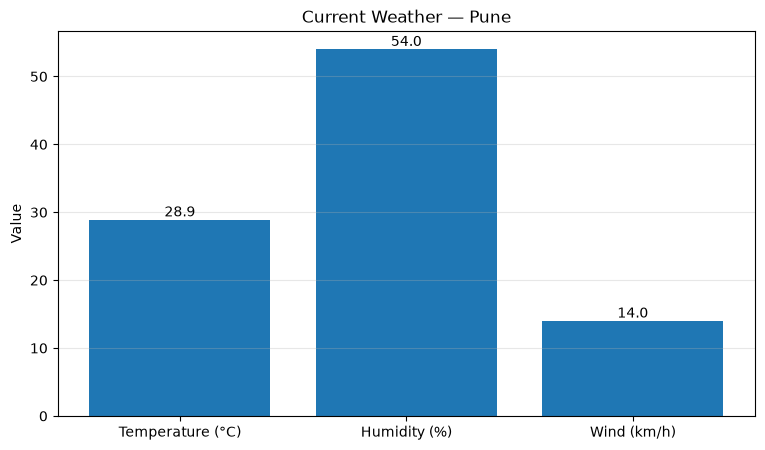

In [7]:

if result:
    temperature = weather["temperature"]
    humidity = weather["humidity"]
    wind_speed = weather["wind_speed"]

    labels = ["Temperature (°C)", "Humidity (%)", "Wind (km/h)"]
    values = [temperature, humidity, wind_speed]

    plt.figure(figsize=(9, 5))
    bars = plt.bar(labels, values)

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.1f}",
            ha="center",
            va="bottom"
        )

    plt.title(f"Current Weather — {location['name']}")
    plt.ylabel("Value")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

## Step 7 — Fetch a short hourly forecast

The agent can also retrieve the next few hours. This gives us a useful time-series visualization.

In [8]:
def get_hourly_forecast(latitude, longitude):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "hourly": "temperature_2m,precipitation_probability",
        "forecast_days": 1,
        "timezone": "auto"
    }

    response = requests.get(url, params=params, timeout=10)
    response.raise_for_status()
    data = response.json()

    return data["hourly"]

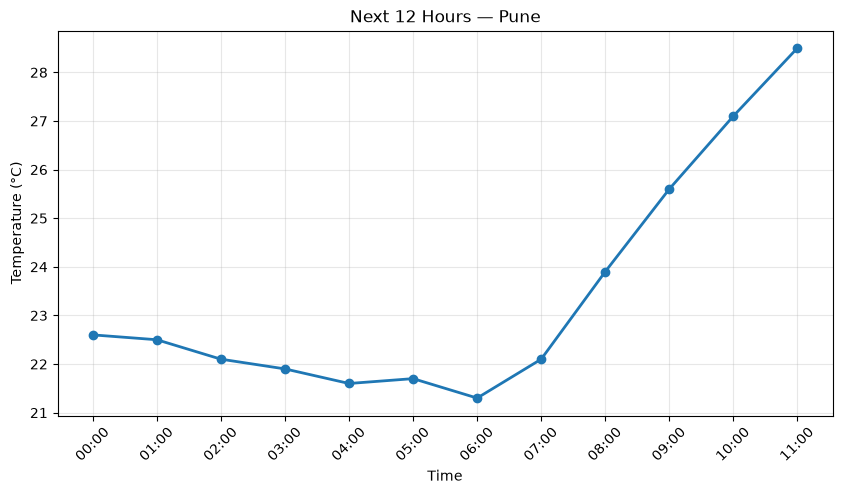

In [9]:
if result:
    try:
        hourly = get_hourly_forecast(
            location["latitude"],
            location["longitude"]
        )

        # Display the next 12 hours
        times = hourly["time"][:12]
        hourly_temps = hourly["temperature_2m"][:12]
        rain_probability = hourly["precipitation_probability"][:12]

        short_times = [time_value[11:16] for time_value in times]

        plt.figure(figsize=(10, 5))
        plt.plot(short_times, hourly_temps, marker="o", linewidth=2)
        plt.xlabel("Time")
        plt.ylabel("Temperature (°C)")
        plt.title(f"Next 12 Hours — {location['name']}")
        plt.grid(True, alpha=0.3)
        plt.xticks(rotation=45)
        plt.show()

    except requests.exceptions.RequestException as error:
        print("Could not fetch the hourly forecast.")
        print("Error:", error)

## Step 8 — Simple weather report function

This gives a clean final report that can be used for any city.

In [10]:
def generate_report(city):
    result = weather_agent(city)

    if result is None:
        return

    location = result["location"]
    weather = result["weather"]

    condition = weather_description(weather["weather_code"])

    print("\n" + "=" * 45)
    print("           WEATHER AGENT REPORT")
    print("=" * 45)
    print(f"City       : {location['name']}, {location['country']}")
    print(f"Temperature: {weather['temperature']} °C")
    print(f"Humidity   : {weather['humidity']} %")
    print(f"Wind speed : {weather['wind_speed']} km/h")
    print(f"Condition  : {condition}")
    print(f"Updated    : {weather['time']}")
    print(f"Timezone   : {weather['timezone']}")
    print("=" * 45)

## Step 9 — Interactive weather agent

Enter a city name and the agent will fetch its current weather. Type `exit` to stop.

In [11]:
while True:
    city = input("Enter a city name (or type 'exit'): ").strip()

    if city.lower() == "exit":
        print("Weather agent stopped.")
        break

    if city == "":
        print("Please enter a city name.")
        continue

    generate_report(city)



           WEATHER AGENT REPORT
City       : Mumbai, India
Temperature: 29.0 °C
Humidity   : 70 %
Wind speed : 19.3 km/h
Condition  : Light drizzle
Updated    : 2026-09-15T14:45
Timezone   : Asia/Kolkata
Weather agent stopped.


## Final result

The completed agent can identify a city, fetch live weather information from a free API, convert the API response into a readable report, and visualize the current and upcoming weather data.

In [12]:
print("Weather Agent")
print("-------------")
print("API connection: Ready")
print("Features: City search, current weather, hourly forecast, visualization")

Weather Agent
-------------
API connection: Ready
Features: City search, current weather, hourly forecast, visualization
